# Clasificación multietiqueta de radiografías de tórax con RNA y HOG

## ChestMNIST — MLPClassifier — Metodología CRISP-DM

**Asignatura:** Inteligencia Artificial  
**Integrantes:** Brayan Charry - Julian Narvaez - Jhoiner Puentes

## Objetivo del notebook

Construir y evaluar una red neuronal artificial para identificar las 14 etiquetas de ChestMNIST a partir de características HOG.

HOG representa los bordes y las orientaciones de los cambios de intensidad mediante un vector de 324 características por radiografía. La clasificación se realiza con MLPClassifier.

Una radiografía puede presentar varias etiquetas positivas simultáneamente.

Este notebook corresponde a la RNA. Las arquitecturas CNN se desarrollan en un Colab independiente.

## Organización

| Fase | Contenido |
|---|---|
| 1. Comprensión del negocio | Problema, objetivos y criterios de evaluación |
| 2. Comprensión de los datos | Particiones, imágenes, etiquetas y calidad |
| 3. Preparación | Extracción de características HOG |
| 4. Modelado | Configuración y entrenamiento de la RNA |
| 5. Evaluación | AUC, umbrales, métricas y análisis de errores |
| 6. Despliegue académico | Guardado, demostración, conclusiones y limitaciones |

# FASE 1. Comprensión del negocio

## 1.1 Problema

¿Qué desempeño alcanza una RNA al identificar las 14 etiquetas de ChestMNIST utilizando características HOG extraídas de radiografías de tórax?

## 1.2 Objetivo general

Evaluar una red neuronal artificial con características HOG para clasificación multietiqueta y comparar posteriormente sus resultados con la CNN.

## 1.3 Objetivos específicos

- Explorar la distribución y calidad de las imágenes y etiquetas.
- Representar cada imagen mediante características HOG.
- Entrenar una RNA utilizando únicamente la partición de entrenamiento.
- Evaluar su capacidad discriminativa mediante AUC.
- Analizar precisión, recall y F1 con umbral inicial y umbrales ajustados en validación.
- Comparar los resultados con una línea base que siempre predice ausencia.
- Conservar el modelo y sus parámetros para reproducir las predicciones.

## 1.4 Interpretación de los errores

Los errores se calculan por etiqueta. Un falso negativo corresponde a una etiqueta positiva que el modelo no detecta. Un falso positivo corresponde a una predicción positiva sin esa etiqueta registrada.

El recall mide la proporción de positivos detectados. La precisión mide la proporción de predicciones positivas correctas. El F1 resume el equilibrio entre ambas.

## 1.5 Criterios de evaluación

Se reportarán AUC macro, precisión, recall y F1 por etiqueta y con promedios macro y micro.

La exactitud binaria y la coincidencia completa se interpretarán junto con la detección de positivos.

Cualquier ajuste de umbral se realizará exclusivamente con validación. El conjunto de prueba no se utilizará para escoger los umbrales.

## 1.6 Alcance y limitaciones

El proyecto es académico y trabaja con imágenes de 28 × 28 píxeles. Sus predicciones no constituyen diagnósticos médicos.

El modelo actual utiliza una configuración de RNA. No se afirmará que es la mejor arquitectura sin realizar una comparación de configuraciones mediante validación.

El conjunto de prueba ya se consultó en la primera versión del notebook. Esto se documentará al interpretar la evaluación ampliada.

## Configuración del entorno

Instalamos medmnist para cargar ChestMNIST y scikit-image
para extraer las características HOG.

In [1]:
!pip install medmnist scikit-image

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 4.0 MB/s eta 0:00:00


# FASE 2. Comprensión de los datos

Cargamos los conjuntos oficiales de entrenamiento y prueba.

Las imágenes se almacenan en las variables X y las etiquetas
en las variables y.

Conservamos las 14 etiquetas binarias por radiografía,
porque varias pueden estar activas simultáneamente.

In [10]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

## 2.1 Carga de entrenamiento y prueba

Se cargan las particiones oficiales de entrenamiento y prueba de ChestMNIST.

Entrenamiento se utiliza para ajustar los pesos de la RNA. Prueba se utiliza para evaluar sus predicciones.

Se conservan las imágenes originales y las 14 etiquetas binarias por radiografía.

In [2]:
from medmnist import ChestMNIST
import numpy as np
import matplotlib.pyplot as plt

# Cargar los conjuntos oficiales
train_dataset = ChestMNIST(split='train', download=True)
test_dataset = ChestMNIST(split='test', download=True)

# Imágenes y etiquetas
X_train_full = train_dataset.imgs
y_train_rna = train_dataset.labels.copy()

X_test_full = test_dataset.imgs
y_test_rna = test_dataset.labels.copy()

# Nombres de las 14 etiquetas
nombres_etiquetas = [
    train_dataset.info['label'][str(i)]
    for i in range(y_train_rna.shape[1])
]

# Comprobar dimensiones
print("Imágenes de entrenamiento:", X_train_full.shape)
print("Etiquetas de entrenamiento:", y_train_rna.shape)

print("\nImágenes de prueba:", X_test_full.shape)
print("Etiquetas de prueba:", y_test_rna.shape)

100%|██████████| 82.8M/82.8M [01:39<00:00, 830kB/s] 


Imágenes de entrenamiento: (78468, 28, 28)
Etiquetas de entrenamiento: (78468, 14)

Imágenes de prueba: (22433, 28, 28)
Etiquetas de prueba: (22433, 14)


## 2.2 Carga de validación

Se incorpora la partición de validación para analizar las probabilidades y elegir los umbrales de decisión.

La RNA existente se entrenó únicamente con entrenamiento. Incorporar validación no modifica sus pesos.

In [11]:
val_dataset = ChestMNIST(split='val', download=True)

X_val_full = val_dataset.imgs
y_val_rna = val_dataset.labels.copy()

print("Imágenes de validación:", X_val_full.shape)
print("Etiquetas de validación:", y_val_rna.shape)

Imágenes de validación: (11219, 28, 28)
Etiquetas de validación: (11219, 14)


# FASE 3. Preparación de los datos

HOG describe las direcciones de los cambios de intensidad
de la imagen mediante histogramas locales.

Utilizamos esta configuración inicial:

- 9 orientaciones.
- Celdas de 7 × 7 píxeles.
- Bloques de 2 × 2 celdas.
- Normalización por bloques L2-Hys.

Como cada imagen tiene 28 × 28 píxeles, obtenemos una
cuadrícula de 4 × 4 celdas. Los bloques se desplazan
una celda y generan un vector de 324 características.

Mostramos la radiografía original y una visualización de HOG.
La RNA recibirá el vector numérico, no la imagen visualizada.

## 3.1 Visualización de HOG

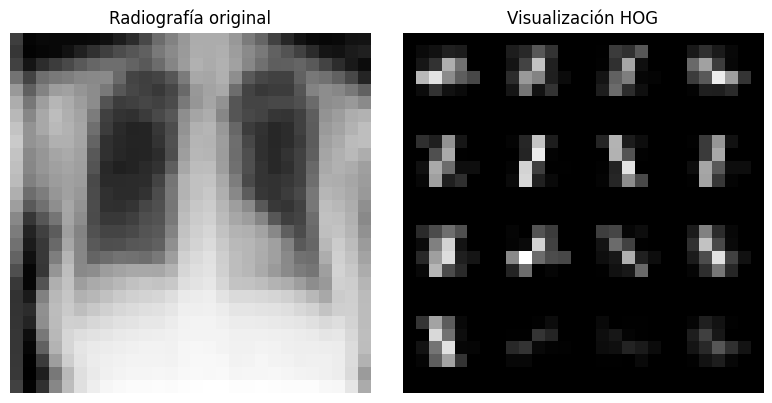

Tamaño de la imagen: (28, 28)
Cantidad de características HOG: 324
Etiquetas de la imagen: [0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [3]:
from skimage.feature import hog

# Seleccionar una imagen de entrenamiento
indice = 0
imagen = X_train_full[indice]

# Normalizar los píxeles
imagen_normalizada = imagen.astype('float32') / 255.0

# Extraer el vector y generar una visualización de HOG
caracteristicas, imagen_hog = hog(
    imagen_normalizada,
    orientations=9,
    pixels_per_cell=(7, 7),
    cells_per_block=(2, 2),
    block_norm='L2-Hys',
    visualize=True,
    feature_vector=True,
    channel_axis=None
)

# Mostrar ambas representaciones
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(imagen, cmap='gray')
axes[0].set_title('Radiografía original')
axes[0].axis('off')

axes[1].imshow(imagen_hog, cmap='gray')
axes[1].set_title('Visualización HOG')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print("Tamaño de la imagen:", imagen.shape)
print("Cantidad de características HOG:", caracteristicas.shape[0])
print("Etiquetas de la imagen:", y_train_rna[indice])

## 3.2 Extracción HOG de entrenamiento y prueba

Transformamos cada radiografía en un vector de 324 características.

Aplicamos los mismos parámetros HOG a entrenamiento y prueba
para que todas las imágenes tengan una representación consistente.

HOG se calcula individualmente por imagen y no requiere aprender
una transformación a partir del conjunto de datos.

Conservamos las 14 etiquetas originales. Las características
obtenidas serán las entradas de la RNA.

In [4]:
# Extraer características de una imagen
def extraer_hog(imagen):
    imagen_normalizada = imagen.astype('float32') / 255.0

    vector = hog(
        imagen_normalizada,
        orientations=9,
        pixels_per_cell=(7, 7),
        cells_per_block=(2, 2),
        block_norm='L2-Hys',
        visualize=False,
        feature_vector=True,
        channel_axis=None
    )

    return vector.astype('float32')


# Procesar un conjunto y mostrar su avance
def procesar_imagenes(imagenes, nombre):
    resultado = np.empty((len(imagenes), 324), dtype='float32')

    for i, imagen in enumerate(imagenes):
        resultado[i] = extraer_hog(imagen)

        if (i + 1) % 10000 == 0 or i + 1 == len(imagenes):
            print(f"{nombre}: {i + 1}/{len(imagenes)} imágenes")

    return resultado


# Obtener las entradas de la RNA
X_train_rna = procesar_imagenes(X_train_full, "Entrenamiento")
X_test_rna = procesar_imagenes(X_test_full, "Prueba")

# Comprobar dimensiones
print("\nCaracterísticas de entrenamiento:", X_train_rna.shape)
print("Características de prueba:", X_test_rna.shape)
print("Etiquetas de entrenamiento:", y_train_rna.shape)
print("Etiquetas de prueba:", y_test_rna.shape)

Entrenamiento: 10000/78468 imágenes
Entrenamiento: 20000/78468 imágenes
Entrenamiento: 30000/78468 imágenes
Entrenamiento: 40000/78468 imágenes
Entrenamiento: 50000/78468 imágenes
Entrenamiento: 60000/78468 imágenes
Entrenamiento: 70000/78468 imágenes
Entrenamiento: 78468/78468 imágenes
Prueba: 10000/22433 imágenes
Prueba: 20000/22433 imágenes
Prueba: 22433/22433 imágenes

Características de entrenamiento: (78468, 324)
Características de prueba: (22433, 324)
Etiquetas de entrenamiento: (78468, 14)
Etiquetas de prueba: (22433, 14)


## 3.3 Extracción HOG de validación

Se aplican exactamente los mismos parámetros HOG utilizados en entrenamiento y prueba. Se obtienen 324 características por imagen.

In [12]:
X_val_rna = procesar_imagenes(
    X_val_full,
    "Validación"
)

print("Características de validación:", X_val_rna.shape)

Validación: 10000/11219 imágenes
Validación: 11219/11219 imágenes
Características de validación: (11219, 324)


# FASE 4. Modelado

Utilizamos MLPClassifier, siguiendo el ejemplo Retina_RNA.

La red recibe las 324 características HOG de cada radiografía
y tiene tres capas ocultas de 64, 16 y 10 neuronas.

Empleamos ReLU como activación de las capas ocultas y Adam
como optimizador.

Conservamos las 14 etiquetas binarias para realizar
clasificación multietiqueta.

## 4.1 Construcción de la RNA

In [5]:
from sklearn.neural_network import MLPClassifier

rna = MLPClassifier(
    solver='adam',
    activation='relu',
    alpha=1e-6,
    tol=1e-4,
    hidden_layer_sizes=(64, 16, 10),
    learning_rate='adaptive',
    learning_rate_init=0.001,
    max_iter=2000,
    momentum=0.9,
    verbose=True,
    random_state=42
)

## 4.2 Entrenamiento

Entrenamos la red utilizando las características HOG y las
etiquetas del conjunto de entrenamiento.

El modelo ajusta sus pesos para reducir la pérdida.
Puede terminar antes del máximo de 2.000 iteraciones
si deja de mejorar según la tolerancia configurada.

No utilizamos el conjunto de prueba para ajustar el modelo.

In [6]:
# Entrenar la RNA con características HOG
rna.fit(X_train_rna, y_train_rna)

print("\nEntrenamiento terminado.")
print("Iteraciones realizadas:", rna.n_iter_)
print("Pérdida final:", rna.loss_)
print("Características de entrada:", rna.n_features_in_)
print("Cantidad de salidas:", rna.n_outputs_)

Iteration 1, loss = 3.71778595
Iteration 2, loss = 2.47646168
Iteration 3, loss = 2.44727609
Iteration 4, loss = 2.43028558
Iteration 5, loss = 2.41993596
Iteration 6, loss = 2.41418235
Iteration 7, loss = 2.40588198
Iteration 8, loss = 2.40190102
Iteration 9, loss = 2.39543464
Iteration 10, loss = 2.39222830
Iteration 11, loss = 2.38616758
Iteration 12, loss = 2.38106108
Iteration 13, loss = 2.37500678
Iteration 14, loss = 2.37128073
Iteration 15, loss = 2.36605858
Iteration 16, loss = 2.36089299
Iteration 17, loss = 2.35638137
Iteration 18, loss = 2.35220848
Iteration 19, loss = 2.34680451
Iteration 20, loss = 2.34300677
Iteration 21, loss = 2.33844624
Iteration 22, loss = 2.33652240
Iteration 23, loss = 2.33242958
Iteration 24, loss = 2.32836769
Iteration 25, loss = 2.32756132
Iteration 26, loss = 2.32470966
Iteration 27, loss = 2.32257372
Iteration 28, loss = 2.31899392
Iteration 29, loss = 2.31727004
Iteration 30, loss = 2.31423716
Iteration 31, loss = 2.31371001
Iteration 32, los

## 4.3 Curva de pérdida

Mostramos la evolución de la pérdida durante el entrenamiento.

El modelo realizó 473 iteraciones y terminó automáticamente
al dejar de mejorar según la tolerancia configurada.

La pérdida final fue aproximadamente 2,1655.
Esta gráfica describe el ajuste al conjunto de entrenamiento;
la evaluación posterior permitirá analizar sus predicciones
sobre imágenes de prueba.

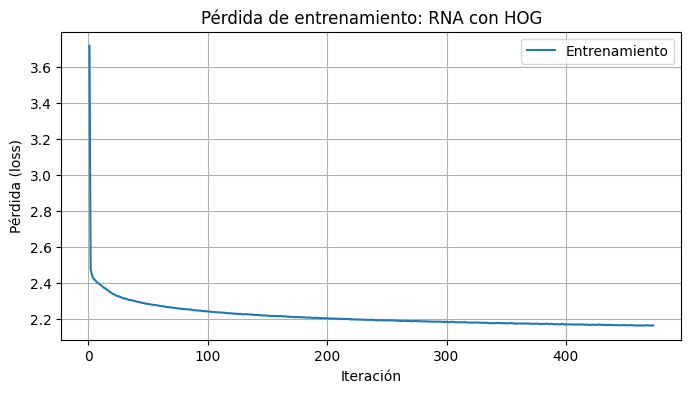

In [7]:
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(rna.loss_curve_) + 1),
    rna.loss_curve_,
    label='Entrenamiento'
)

plt.title('Pérdida de entrenamiento: RNA con HOG')
plt.xlabel('Iteración')
plt.ylabel('Pérdida (loss)')
plt.legend()
plt.grid(True)
plt.show()

# FASE 5. Evaluación

## 5.1 Evaluación inicial en validación

Se obtienen las probabilidades de las 14 etiquetas con predict_proba y se aplica un umbral inicial de 0,5.

La AUC se calcula con las probabilidades. Precisión, recall y F1 se calculan con las predicciones binarias.

No se utiliza argmax, porque las etiquetas pueden estar activas simultáneamente.

In [13]:
prob_val_rna = rna.predict_proba(X_val_rna)
pred_val_rna_05 = (prob_val_rna >= 0.5).astype(int)

auc_val_rna = roc_auc_score(
    y_val_rna,
    prob_val_rna,
    average='macro'
)

print(f"AUC macro de validación: {auc_val_rna:.4f}\n")

print(classification_report(
    y_val_rna,
    pred_val_rna_05,
    target_names=nombres_etiquetas,
    digits=4,
    zero_division=0
))

AUC macro de validación: 0.6776

               precision    recall  f1-score   support

  atelectasis     0.2328    0.0241    0.0437      1119
 cardiomegaly     0.2500    0.0333    0.0588       240
     effusion     0.3601    0.2012    0.2582      1292
 infiltration     0.3789    0.0357    0.0652      2018
         mass     0.3333    0.0032    0.0063       625
       nodule     0.0000    0.0000    0.0000       613
    pneumonia     0.0000    0.0000    0.0000       133
 pneumothorax     0.0714    0.0040    0.0075       504
consolidation     0.2857    0.0045    0.0088       447
        edema     0.1429    0.0200    0.0351       200
    emphysema     0.0000    0.0000    0.0000       208
     fibrosis     0.0000    0.0000    0.0000       166
      pleural     0.0000    0.0000    0.0000       372
       hernia     0.0000    0.0000    0.0000        41

    micro avg     0.3339    0.0473    0.0828      7978
    macro avg     0.1468    0.0233    0.0346      7978
 weighted avg     0.2446    0.

### Interpretación de la evaluación inicial

La RNA con HOG obtuvo una AUC macro de validación de 0,6776.

Con umbral 0,5 presentó precisión micro de 0,3339, recall micro de 0,0473 y F1 micro de 0,0828. Varias etiquetas tuvieron recall cero.

Estos resultados muestran que la capacidad discriminativa de las probabilidades no garantiza una detección adecuada con el umbral inicial.

## 5.2 Ajuste de umbrales con validación

Se utiliza el mismo procedimiento aplicado a la CNN: para cada etiqueta se busca el umbral más alto, entre 0,50 y 0,01, que alcance recall de al menos 0,80.

La meta es exploratoria y procede del notebook de referencia; no representa un criterio clínico.

Si ningún umbral del intervalo alcanza la meta, se conserva 0,01 y se informa que no se logró.

Se reportan precisión, recall, F1 y falsos positivos para observar el costo de aumentar la detección. Los umbrales se eligen exclusivamente con validación.

In [14]:
NUM_ETIQUETAS = y_train_rna.shape[1]
META_RECALL = 0.80

umbrales_busqueda = np.round(
    np.arange(0.50, 0.009, -0.01), 2
)

umbrales_rna = np.full(NUM_ETIQUETAS, 0.5)
filas_umbrales_rna = []

for j, etiqueta in enumerate(nombres_etiquetas):
    reales = y_val_rna[:, j]
    probabilidades = prob_val_rna[:, j]
    positivos = int(reales.sum())

    if positivos == 0:
        umbral = 0.5
        cumple = False
    else:
        umbral = float(umbrales_busqueda[-1])
        cumple = False

        for candidato in umbrales_busqueda:
            pred = probabilidades >= candidato

            vp = int(
                ((reales == 1) & pred).sum()
            )

            if vp / positivos >= META_RECALL:
                umbral = float(candidato)
                cumple = True
                break

    umbrales_rna[j] = umbral
    pred = (probabilidades >= umbral).astype(int)

    filas_umbrales_rna.append({
        'Etiqueta': etiqueta,
        'Positivos reales': positivos,
        'Umbral': umbral,
        'Precisión': precision_score(
            reales, pred, zero_division=0
        ),
        'Recall': recall_score(
            reales, pred, zero_division=0
        ),
        'F1': f1_score(
            reales, pred, zero_division=0
        ),
        'Falsos positivos': int(
            ((reales == 0) & (pred == 1)).sum()
        ),
        'Meta alcanzada': (
            'Sin positivos' if positivos == 0
            else 'Sí' if cumple else 'No'
        )
    })

tabla_umbrales_rna = pd.DataFrame(filas_umbrales_rna)
display(tabla_umbrales_rna.round(4))

pred_val_rna_aj = (
    prob_val_rna >= umbrales_rna
).astype(int)

print("\nVALIDACIÓN — UMBRALES AJUSTADOS\n")

print(classification_report(
    y_val_rna,
    pred_val_rna_aj,
    target_names=nombres_etiquetas,
    digits=4,
    zero_division=0
))

# Crear una carpeta independiente de los resultados de CNN
from pathlib import Path

RESULTADOS_RNA = Path('resultados_rna')
RESULTADOS_RNA.mkdir(parents=True, exist_ok=True)

tabla_umbrales_rna.to_csv(
    RESULTADOS_RNA / 'umbrales_validacion.csv',
    index=False
)

,Etiqueta,Positivos reales,Umbral,Precisión,Recall,F1,Falsos positivos,Meta alcanzada
0,atelectasis,1119,0.06,0.1405,0.8097,0.2395,5541,Sí
1,cardiomegaly,240,0.01,0.0439,0.7125,0.0828,3721,No
2,effusion,1292,0.06,0.1994,0.8080,0.3199,4191,Sí
3,infiltration,2018,0.11,0.2067,0.8216,0.3303,6362,Sí
4,mass,625,0.02,0.0634,0.8832,0.1183,8157,Sí
5,nodule,613,0.04,0.0592,0.8173,0.1104,7964,Sí
6,pneumonia,133,0.01,0.0180,0.6165,0.0350,4465,No
7,pneumothorax,504,0.01,0.0569,0.8651,0.1068,7221,Sí
8,consolidation,447,0.02,0.0640,0.8188,0.1187,5354,Sí
9,edema,200,0.01,0.0419,0.8050,0.0797,3678,Sí



VALIDACIÓN — UMBRALES AJUSTADOS

               precision    recall  f1-score   support

  atelectasis     0.1405    0.8097    0.2395      1119
 cardiomegaly     0.0439    0.7125    0.0828       240
     effusion     0.1994    0.8080    0.3199      1292
 infiltration     0.2067    0.8216    0.3303      2018
         mass     0.0634    0.8832    0.1183       625
       nodule     0.0592    0.8173    0.1104       613
    pneumonia     0.0180    0.6165    0.0350       133
 pneumothorax     0.0569    0.8651    0.1068       504
consolidation     0.0640    0.8188    0.1187       447
        edema     0.0419    0.8050    0.0797       200
    emphysema     0.0240    0.7933    0.0465       208
     fibrosis     0.0197    0.7711    0.0384       166
      pleural     0.0376    0.8925    0.0722       372
       hernia     0.0000    0.0000    0.0000        41

    micro avg     0.0765    0.8150    0.1399      7978
    macro avg     0.0697    0.7439    0.1213      7978
 weighted avg     0.1265    0

### Interpretación del ajuste de umbrales

El ajuste aumentó el recall micro de 0,0473 a 0,8150 y el F1 micro de 0,0828 a 0,1399. Sin embargo, la precisión micro descendió de 0,3339 a 0,0765.

Esto significa que se detectan más positivos, pero la mayoría de las predicciones positivas son falsas alarmas.

Nueve etiquetas alcanzaron recall de al menos 0,80 en validación. Cardiomegaly, pneumonia, emphysema, fibrosis y hernia no alcanzaron esa meta dentro del intervalo [0,01, 0,50].

Se conservan estos umbrales para la evaluación en prueba. No se modificarán utilizando los resultados de prueba.

## 5.3 Evaluación ampliada en el conjunto de prueba

Se comparan una línea base que siempre predice ausencia, la RNA con umbral 0,5 y la RNA con los umbrales elegidos en validación.

Se utilizan las mismas métricas que en el notebook CNN para facilitar la comparación posterior.

El conjunto de prueba ya fue consultado en la versión inicial del proyecto. Esta evaluación amplía el análisis del mismo modelo; los nuevos umbrales se han elegido exclusivamente con validación.

In [15]:
# Calcular probabilidades de las 14 etiquetas
prob_test_rna = rna.predict_proba(X_test_rna)

pred_test_rna_05 = (prob_test_rna >= 0.5).astype(int)
pred_test_rna_aj = (
    prob_test_rna >= umbrales_rna
).astype(int)

pred_test_base = np.zeros_like(y_test_rna)

auc_test_rna = roc_auc_score(
    y_test_rna,
    prob_test_rna,
    average='macro'
)


def resumir_prueba_rna(nombre, predicciones, auc):
    return {
        'Alternativa': nombre,
        'AUC macro': auc,
        'Precisión micro': precision_score(
            y_test_rna, predicciones,
            average='micro', zero_division=0
        ),
        'Recall micro': recall_score(
            y_test_rna, predicciones,
            average='micro', zero_division=0
        ),
        'F1 micro': f1_score(
            y_test_rna, predicciones,
            average='micro', zero_division=0
        ),
        'F1 macro': f1_score(
            y_test_rna, predicciones,
            average='macro', zero_division=0
        ),
        'Exactitud binaria': float(
            (y_test_rna == predicciones).mean()
        ),
        'Coincidencia exacta': accuracy_score(
            y_test_rna, predicciones
        ),
        'Verdaderos positivos': int(
            ((y_test_rna == 1) & (predicciones == 1)).sum()
        ),
        'Falsos positivos': int(
            ((y_test_rna == 0) & (predicciones == 1)).sum()
        ),
        'Falsos negativos': int(
            ((y_test_rna == 1) & (predicciones == 0)).sum()
        )
    }


tabla_test_rna = pd.DataFrame([
    resumir_prueba_rna(
        'Siempre ausencia', pred_test_base, 0.5
    ),
    resumir_prueba_rna(
        'RNA — umbral 0,5', pred_test_rna_05, auc_test_rna
    ),
    resumir_prueba_rna(
        'RNA — umbrales ajustados',
        pred_test_rna_aj,
        auc_test_rna
    )
])

display(tabla_test_rna.round(4))

print("\nPRUEBA — UMBRALES AJUSTADOS\n")

print(classification_report(
    y_test_rna,
    pred_test_rna_aj,
    target_names=nombres_etiquetas,
    digits=4,
    zero_division=0
))

# Compatibilidad con las matrices originales:
# y_pred_rna mantiene las predicciones con umbral 0,5
y_pred_rna = pred_test_rna_05
exactitud_rna = accuracy_score(y_test_rna, y_pred_rna)

tabla_test_rna.to_csv(
    RESULTADOS_RNA / 'evaluacion_test.csv',
    index=False
)

np.savez_compressed(
    RESULTADOS_RNA / 'predicciones_test_RNA.npz',
    y_real=y_test_rna,
    probabilidades=prob_test_rna,
    pred_05=pred_test_rna_05,
    pred_ajustadas=pred_test_rna_aj,
    umbrales=umbrales_rna,
    etiquetas=np.asarray(nombres_etiquetas)
)

,Alternativa,AUC macro,Precisión micro,Recall micro,F1 micro,F1 macro,Exactitud binaria,Coincidencia exacta,Verdaderos positivos,Falsos positivos,Falsos negativos
0,Siempre ausencia,0.5000,0.0000,0.0000,0.0000,0.0000,0.9474,0.5317,0,0,16510
1,"RNA — umbral 0,5",0.6704,0.3302,0.0451,0.0793,0.0350,0.9450,0.5174,744,1509,15766
2,RNA — umbrales ajustados,0.6704,0.0786,0.8193,0.1435,0.1252,0.4858,0.0192,13526,158519,2984



PRUEBA — UMBRALES AJUSTADOS

               precision    recall  f1-score   support

  atelectasis     0.1503    0.8157    0.2538      2420
 cardiomegaly     0.0515    0.7285    0.0962       582
     effusion     0.2083    0.8090    0.3313      2754
 infiltration     0.1999    0.8268    0.3219      3938
         mass     0.0566    0.8694    0.1063      1133
       nodule     0.0648    0.8165    0.1201      1335
    pneumonia     0.0151    0.5785    0.0294       242
 pneumothorax     0.0619    0.8898    0.1157      1089
consolidation     0.0688    0.8412    0.1271       957
        edema     0.0424    0.8039    0.0806       413
    emphysema     0.0287    0.7878    0.0553       509
     fibrosis     0.0208    0.7403    0.0405       362
      pleural     0.0369    0.8896    0.0709       734
       hernia     0.0021    0.0238    0.0039        42

    micro avg     0.0786    0.8193    0.1435     16510
    macro avg     0.0720    0.7443    0.1252     16510
 weighted avg     0.1277    0.819

### Interpretación de la evaluación de prueba

La RNA con HOG obtuvo una AUC macro de 0,6704 en prueba, cercana al resultado de validación de 0,6776.

Con umbral 0,5 presentó precisión micro de 0,3302, recall micro de 0,0451 y F1 micro de 0,0793. Detectó correctamente 744 de las 16.510 etiquetas positivas.

Con los umbrales elegidos en validación, el recall micro aumentó a 0,8193 y el F1 micro a 0,1435. Sin embargo, la precisión micro descendió a 0,0786: la mayoría de las predicciones positivas fueron falsas alarmas.

El recall macro fue 0,7443, inferior al recall micro. El desempeño varía entre etiquetas; por ejemplo, hernia presentó recall de 0,0238.

La exactitud binaria con umbral 0,5 fue 0,9450, inferior a la línea base que siempre predice ausencia (0,9474). Este resultado confirma que la exactitud aislada no permite valorar adecuadamente la detección de positivos.

## 5.4 Matrices de confusión por etiqueta

Se construyen las matrices utilizando los umbrales ajustados exclusivamente con validación.

Las filas representan las etiquetas reales y las columnas las predicciones.

| | Predicción 0 | Predicción 1 |
|---|---|---|
| Real 0 | Verdaderos negativos | Falsos positivos |
| Real 1 | Falsos negativos | Verdaderos positivos |

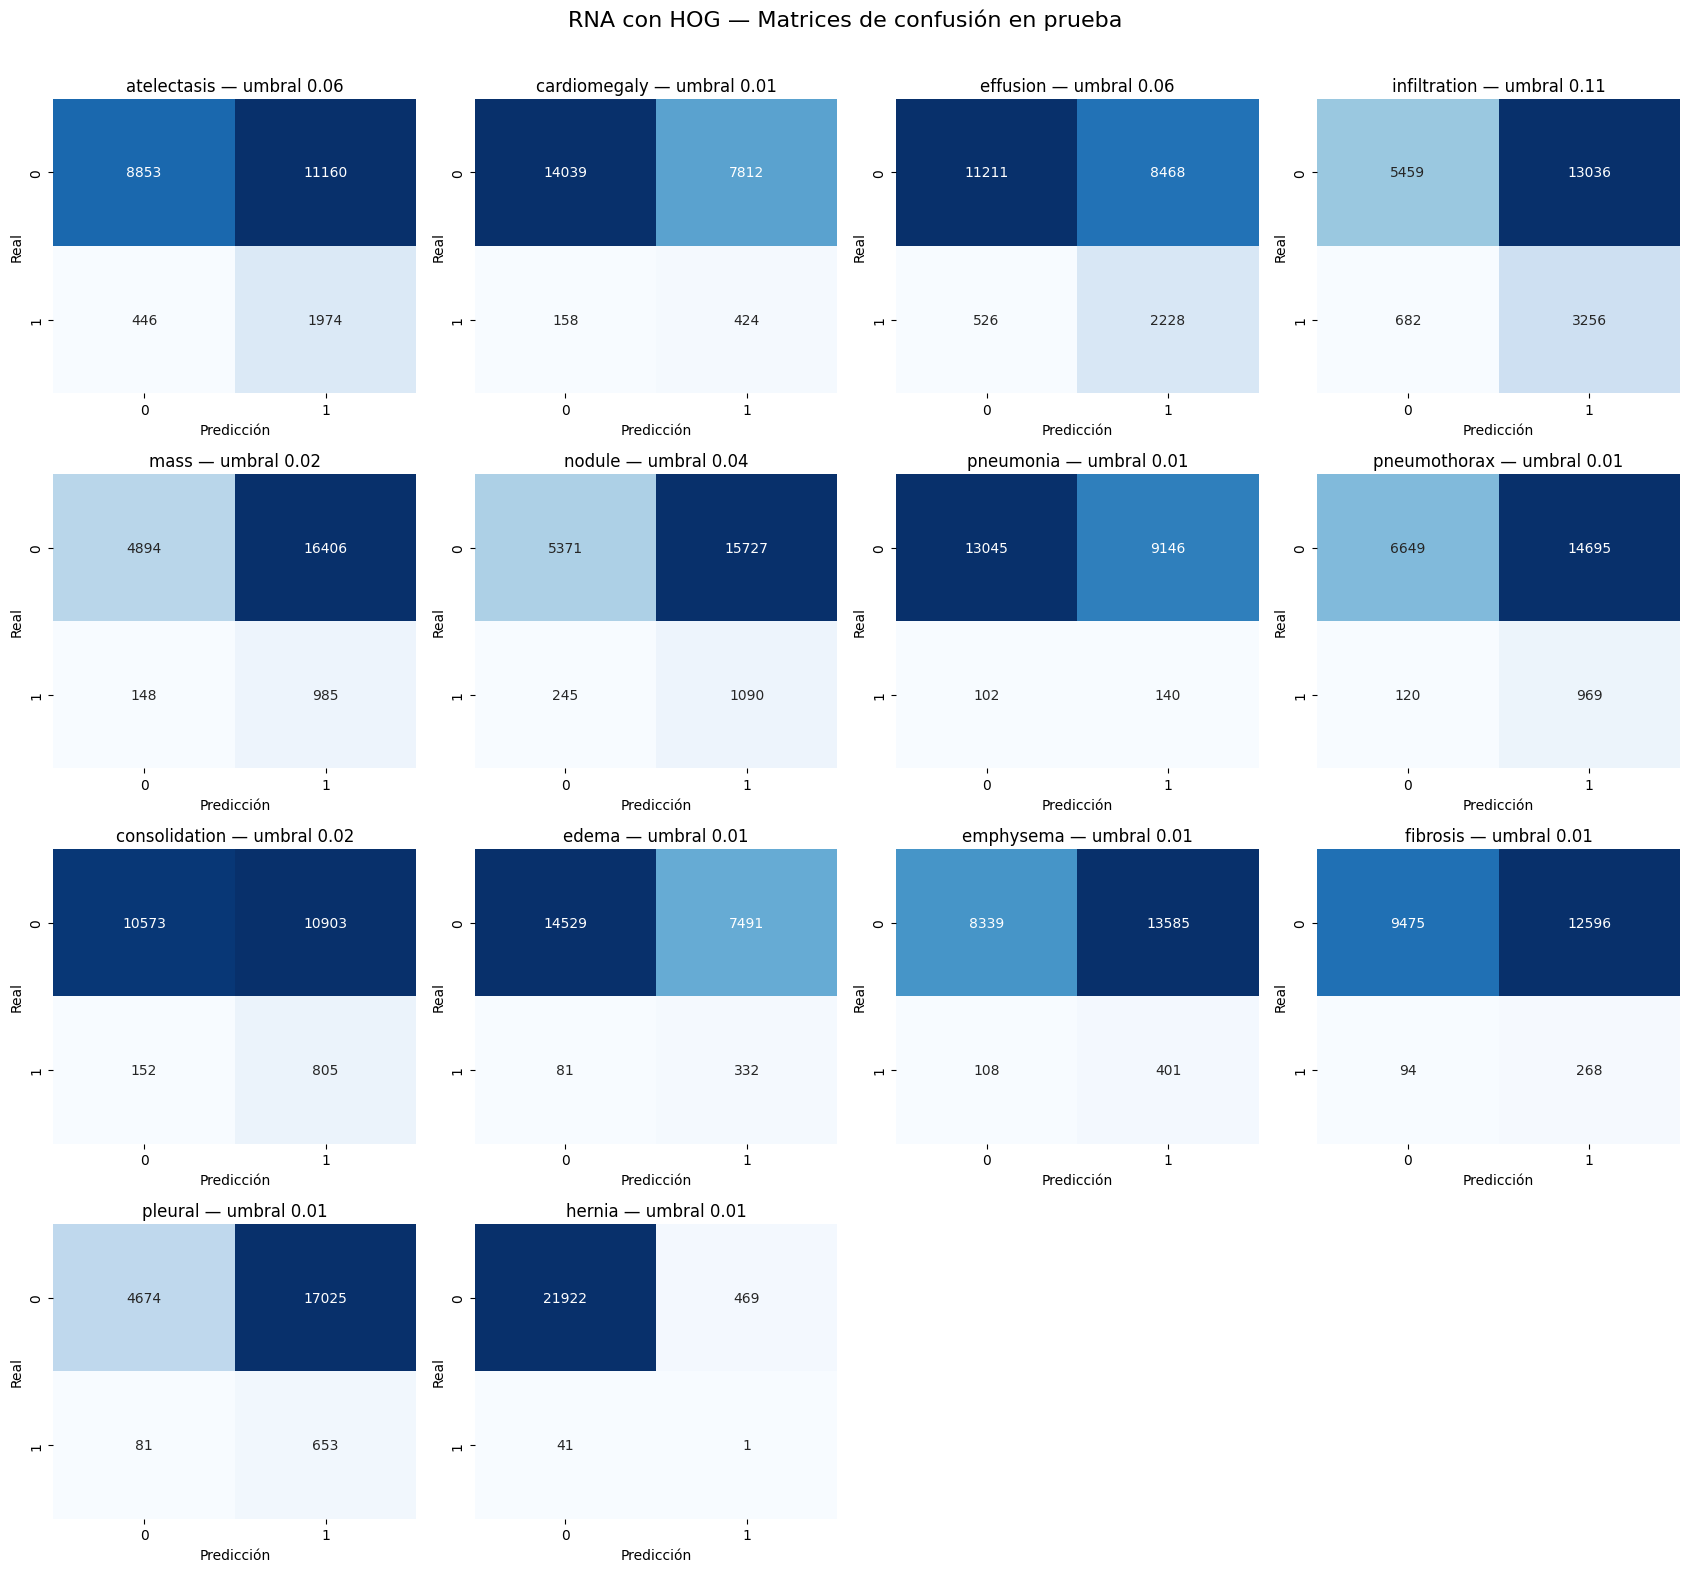

,Etiqueta,Umbral,VN,FP,FN,VP
0,atelectasis,0.06,8853,11160,446,1974
1,cardiomegaly,0.01,14039,7812,158,424
2,effusion,0.06,11211,8468,526,2228
3,infiltration,0.11,5459,13036,682,3256
4,mass,0.02,4894,16406,148,985
5,nodule,0.04,5371,15727,245,1090
6,pneumonia,0.01,13045,9146,102,140
7,pneumothorax,0.01,6649,14695,120,969
8,consolidation,0.02,10573,10903,152,805
9,edema,0.01,14529,7491,81,332


In [16]:
from sklearn.metrics import multilabel_confusion_matrix
import seaborn as sns

matrices_rna = multilabel_confusion_matrix(
    y_test_rna,
    pred_test_rna_aj
)

fig, axes = plt.subplots(4, 4, figsize=(17, 16))
filas_matrices_rna = []

for j, etiqueta in enumerate(nombres_etiquetas):
    ax = axes.flat[j]
    matriz = matrices_rna[j]

    sns.heatmap(
        matriz,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        xticklabels=['0', '1'],
        yticklabels=['0', '1'],
        ax=ax
    )

    ax.set_title(
        f'{etiqueta} — umbral {umbrales_rna[j]:.2f}'
    )
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Real')

    vn, fp, fn, vp = matriz.ravel()

    filas_matrices_rna.append({
        'Etiqueta': etiqueta,
        'Umbral': umbrales_rna[j],
        'VN': int(vn),
        'FP': int(fp),
        'FN': int(fn),
        'VP': int(vp)
    })

for ax in axes.flat[NUM_ETIQUETAS:]:
    ax.axis('off')

fig.suptitle(
    'RNA con HOG — Matrices de confusión en prueba',
    fontsize=16
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

tabla_matrices_rna = pd.DataFrame(filas_matrices_rna)
display(tabla_matrices_rna)

tabla_matrices_rna.to_csv(
    RESULTADOS_RNA / 'matrices_confusion_test.csv',
    index=False
)

### Interpretación de las matrices

Los umbrales ajustados aumentan la detección de positivos, pero generan numerosos falsos positivos.

Effusion presenta 2.228 verdaderos positivos y 8.468 falsos positivos. Mass detecta 985 de sus 1.133 positivos, pero produce 16.406 falsas alarmas.

El desempeño varía entre etiquetas: hernia identifica solamente uno de los 42 positivos.

Los conteos corresponden a decisiones por etiqueta, no a pacientes diferentes.

## 5.5 Curvas ROC y AUC por etiqueta

Se calcula una curva ROC para cada etiqueta utilizando las probabilidades de prueba.

La curva relaciona el recall con la tasa de falsos positivos al variar el umbral. La diagonal representa una puntuación sin capacidad discriminativa, con AUC de 0,5.

El punto rojo señala el resultado del umbral elegido en validación. Estas curvas describen el desempeño final y no se utilizarán para cambiar los umbrales.

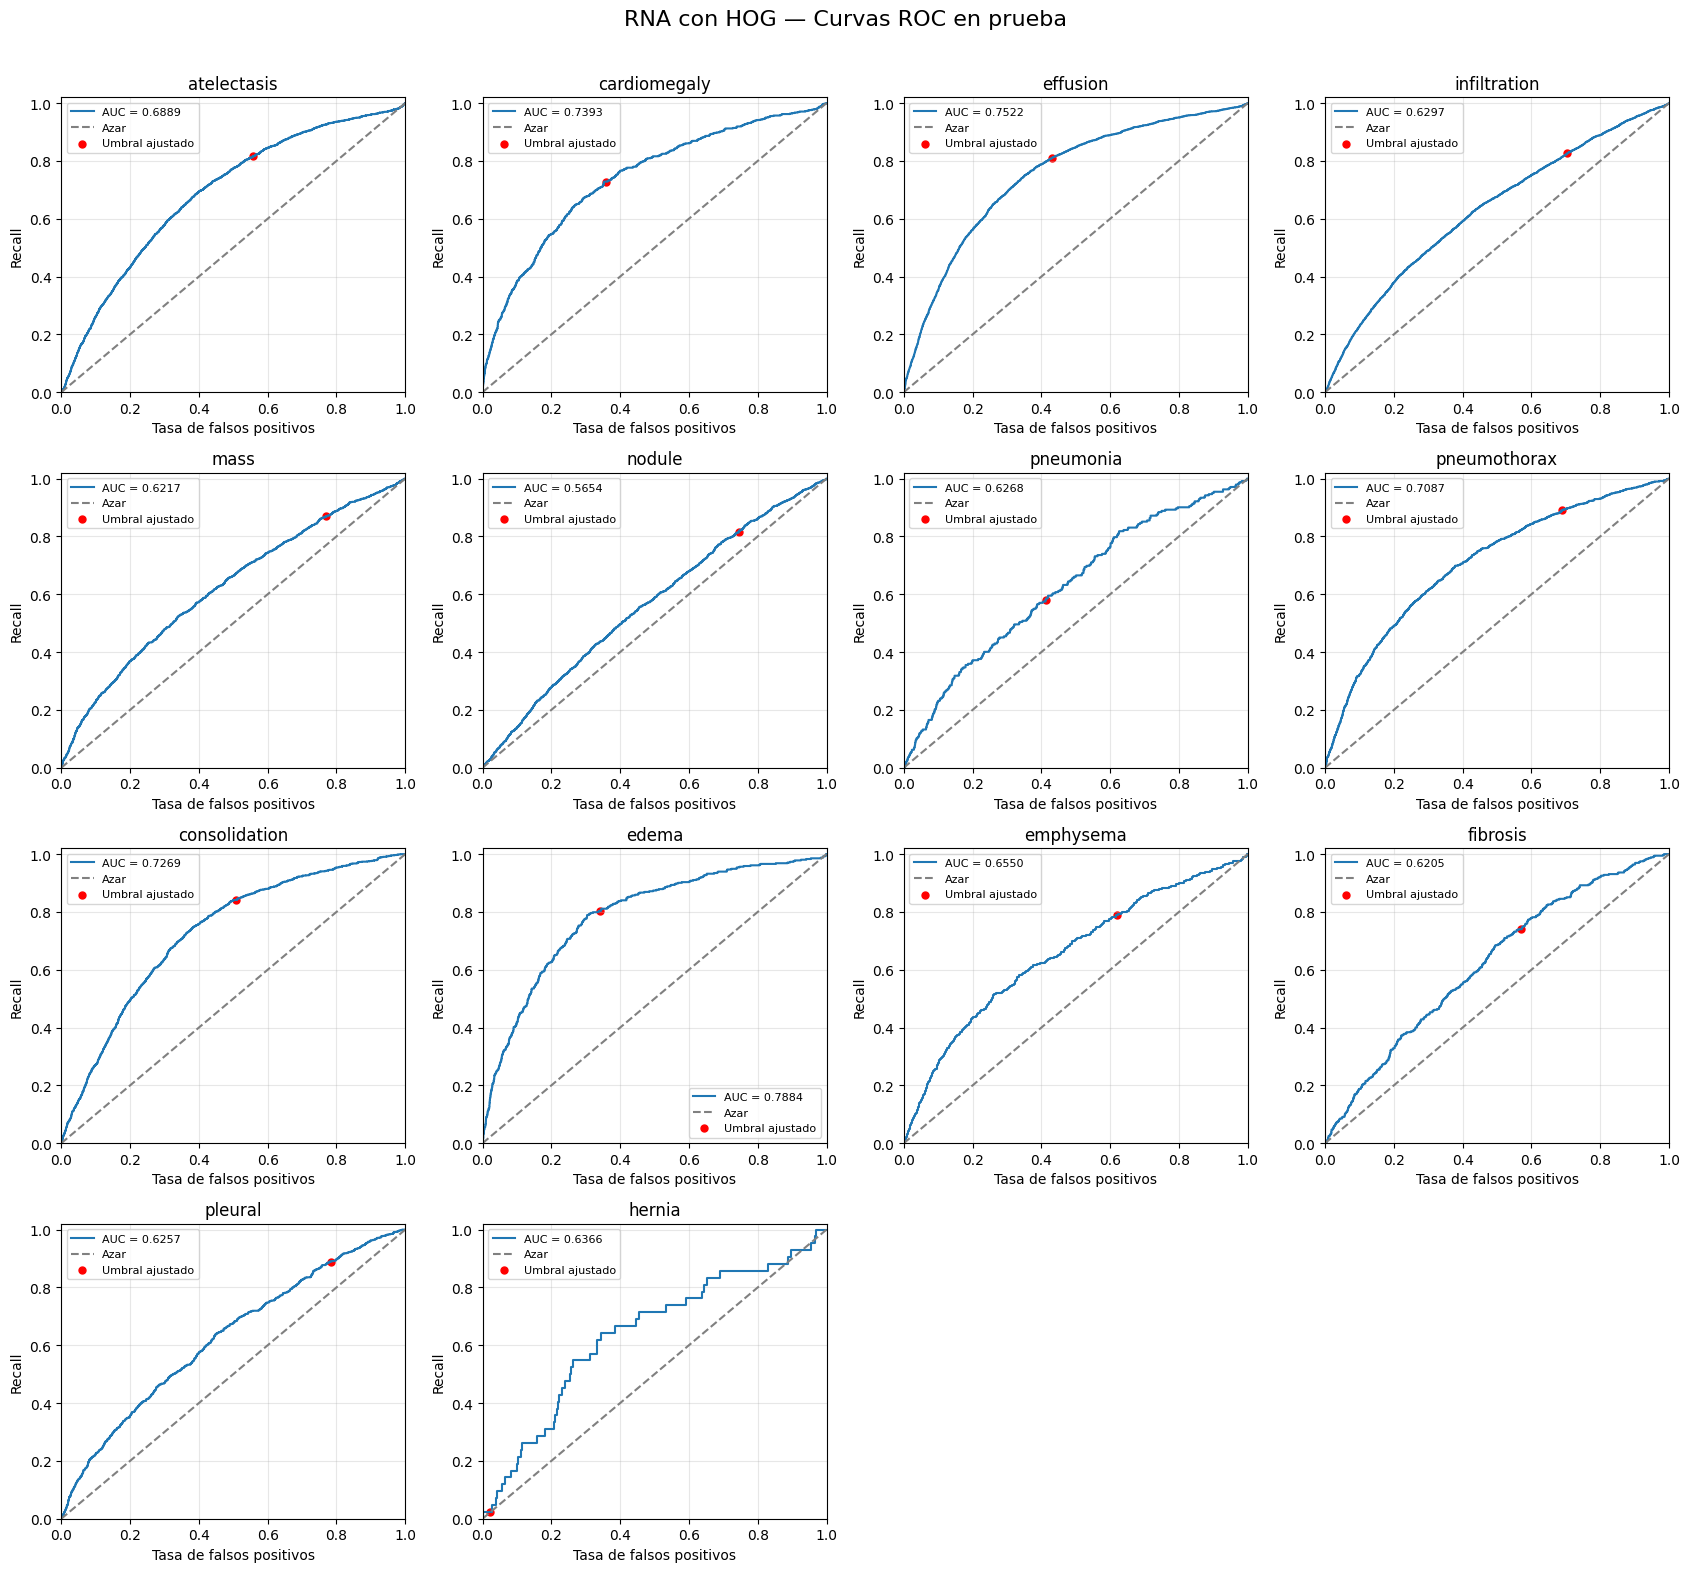

,Etiqueta,AUC
9,edema,0.7884
2,effusion,0.7522
1,cardiomegaly,0.7393
8,consolidation,0.7269
7,pneumothorax,0.7087
0,atelectasis,0.6889
10,emphysema,0.6550
13,hernia,0.6366
3,infiltration,0.6297
6,pneumonia,0.6268


In [17]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(4, 4, figsize=(17, 16))
filas_auc_rna = []

for j, etiqueta in enumerate(nombres_etiquetas):
    ax = axes.flat[j]
    reales = y_test_rna[:, j]
    probabilidades = prob_test_rna[:, j]

    if len(np.unique(reales)) < 2:
        ax.set_title(f'{etiqueta}: AUC no definida')
        filas_auc_rna.append({
            'Etiqueta': etiqueta,
            'AUC': np.nan
        })
        continue

    fpr, tpr, _ = roc_curve(reales, probabilidades)
    auc_etiqueta = roc_auc_score(reales, probabilidades)

    ax.plot(
        fpr, tpr,
        label=f'AUC = {auc_etiqueta:.4f}'
    )
    ax.plot(
        [0, 1], [0, 1],
        linestyle='--',
        color='gray',
        label='Azar'
    )

    vn, fp, fn, vp = matrices_rna[j].ravel()

    ax.scatter(
        fp / (fp + vn),
        vp / (vp + fn),
        color='red',
        s=25,
        label='Umbral ajustado'
    )

    ax.set_title(etiqueta)
    ax.set_xlabel('Tasa de falsos positivos')
    ax.set_ylabel('Recall')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

    filas_auc_rna.append({
        'Etiqueta': etiqueta,
        'AUC': auc_etiqueta
    })

for ax in axes.flat[NUM_ETIQUETAS:]:
    ax.axis('off')

fig.suptitle(
    'RNA con HOG — Curvas ROC en prueba',
    fontsize=16
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

tabla_auc_rna = pd.DataFrame(filas_auc_rna)

display(
    tabla_auc_rna.sort_values(
        'AUC', ascending=False
    ).round(4)
)

tabla_auc_rna.to_csv(
    RESULTADOS_RNA / 'auc_por_etiqueta.csv',
    index=False
)

### Interpretación de la AUC por etiqueta

Las mayores AUC de prueba fueron edema (0,7884), effusion (0,7522) y cardiomegaly (0,7393). La menor fue nodule (0,5654).

La AUC macro fue 0,6704, pero el desempeño varía entre etiquetas. Una AUC superior a 0,5 indica capacidad discriminativa en este conjunto, sin garantizar una buena precisión o sensibilidad en el umbral utilizado.

# FASE 6. Despliegue académico y conclusiones

## 6.1 Conclusiones

Se construyó una RNA con MLPClassifier y tres capas ocultas de 64, 16 y 10 neuronas. Cada radiografía se representó mediante 324 características HOG, conservando sus 14 etiquetas binarias.

El entrenamiento terminó después de 473 iteraciones, con una pérdida final aproximada de 2,1655. La curva disponible describe únicamente el entrenamiento y no permite diagnosticar por sí sola el sobreajuste.

La RNA obtuvo AUC macro de 0,6776 en validación y 0,6704 en prueba.

Con umbral 0,5 detectó 744 de las 16.510 etiquetas positivas de prueba, con precisión micro de 0,3302, recall micro de 0,0451 y F1 micro de 0,0793.

Los umbrales elegidos en validación aumentaron el recall micro a 0,8193 y el F1 micro a 0,1435. Sin embargo, la precisión micro descendió a 0,0786, mostrando una elevada cantidad de falsas alarmas.

La RNA aprendió patrones discriminativos a partir de HOG, pero su desempeño presenta limitaciones importantes para convertir las probabilidades en decisiones.

## 6.2 Limitaciones

- Imágenes de baja resolución: 28 × 28 píxeles.
- Frecuencias diferentes entre las 14 etiquetas.
- Se evaluó una configuración de RNA y una semilla; no se puede afirmar que sea la mejor arquitectura ni medir su estabilidad entre ejecuciones.
- La pérdida registrada corresponde únicamente al entrenamiento.
- La búsqueda de umbrales se limitó al intervalo [0,01, 0,50].
- Los umbrales se eligieron y analizaron sobre la misma partición de validación.
- El conjunto de prueba ya se había consultado en la versión inicial.
- No se realizó validación externa.
- El proyecto es académico y sus predicciones no constituyen diagnósticos médicos.

## 6.3 Trabajo futuro

Comparar configuraciones de RNA utilizando validación, repetir los experimentos con distintas semillas y estudiar estrategias de manejo del desbalance multietiqueta.

Comparar la RNA con las CNN utilizando las mismas imágenes, etiquetas y métricas. La comparación debe considerar que la CNN se seleccionó entre varias arquitecturas y semillas, mientras que la RNA utiliza una configuración.

## 6.4 Guardado del modelo y del procesamiento

Se guarda la RNA entrenada junto con los parámetros HOG, el orden de las etiquetas y los umbrales elegidos en validación.

Para reutilizar el modelo se debe aplicar a cada imagen exactamente la misma extracción HOG utilizada durante el entrenamiento.

In [18]:
import joblib
import sklearn
import skimage

config_hog = {
    'orientations': 9,
    'pixels_per_cell': (7, 7),
    'cells_per_block': (2, 2),
    'block_norm': 'L2-Hys',
    'visualize': False,
    'feature_vector': True,
    'channel_axis': None
}

paquete_rna = {
    'modelo': rna,
    'config_hog': config_hog,
    'normalizacion': 'float32 / 255.0 antes de HOG',
    'forma_imagen': (28, 28),
    'numero_caracteristicas': 324,
    'etiquetas': list(nombres_etiquetas),
    'umbrales': umbrales_rna.copy(),
    'auc_validacion': float(auc_val_rna),
    'auc_test': float(auc_test_rna),
    'version_sklearn': sklearn.__version__,
    'version_skimage': skimage.__version__
}

ruta_modelo_rna = RESULTADOS_RNA / 'ChestMNIST_RNA_HOG.joblib'
joblib.dump(paquete_rna, ruta_modelo_rna)

# Recuperar el modelo guardado
paquete_recuperado = joblib.load(ruta_modelo_rna)

# Repetir el procesamiento de una imagen con la configuración guardada
imagen_control = X_test_full[0].astype('float32') / 255.0

vector_control = hog(
    imagen_control,
    **paquete_recuperado['config_hog']
).astype('float32')

prob_control = paquete_recuperado['modelo'].predict_proba(
    vector_control.reshape(1, -1)
)

np.testing.assert_allclose(
    prob_control,
    prob_test_rna[:1],
    rtol=1e-5,
    atol=1e-6
)

pd.DataFrame({
    'Pérdida': rna.loss_curve_
}).rename_axis('Iteración desde cero').to_csv(
    RESULTADOS_RNA / 'perdida_entrenamiento.csv'
)

print("Modelo guardado:", ruta_modelo_rna)
print("Comprobación correcta: HOG y RNA reproducen las probabilidades.")

Modelo guardado: resultados_rna/ChestMNIST_RNA_HOG.joblib
Comprobación correcta: HOG y RNA reproducen las probabilidades.


## Comparación final: RNA con HOG y CNN

Se comparan los resultados de ambos modelos sobre las mismas imágenes de prueba.

Precisión, recall y F1 corresponden a los umbrales elegidos por separado para cada modelo utilizando la misma regla en validación. La AUC se calcula con las probabilidades y no depende del umbral.

La CNN fue seleccionada entre tres arquitecturas y tres semillas. La RNA corresponde a una configuración y una semilla, lo que limita el alcance de la comparación.

,RNA con HOG,CNN — VGG compacta
Métrica,,
AUC macro,0.6704,0.7654
Precisión micro,0.0786,0.0975
Recall micro,0.8193,0.8390
F1 micro,0.1435,0.1747
F1 macro,0.1252,0.1563


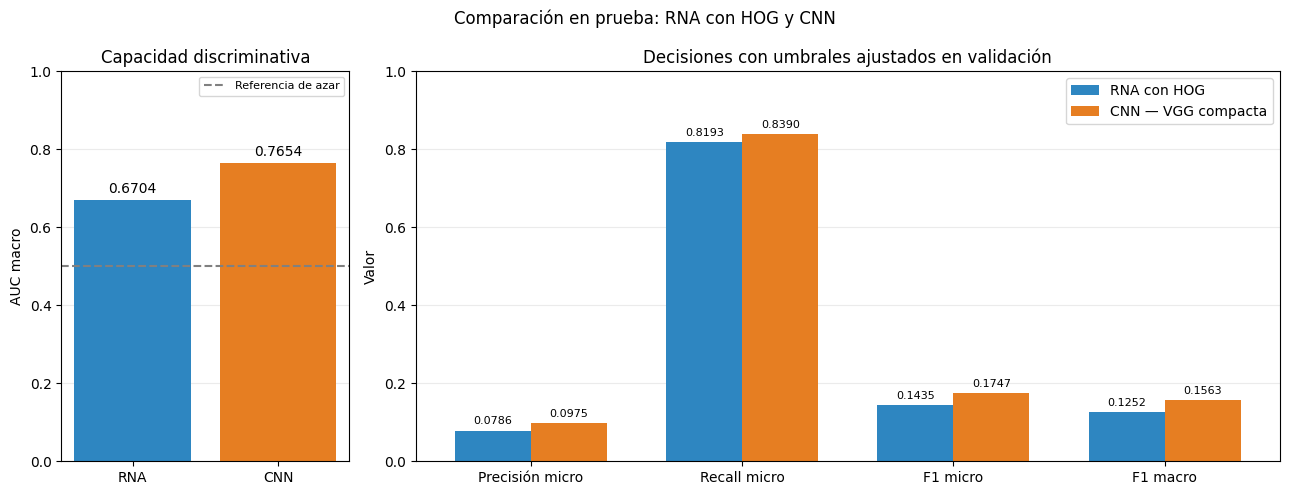

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

comparacion = pd.DataFrame({
    'Métrica': [
        'AUC macro',
        'Precisión micro',
        'Recall micro',
        'F1 micro',
        'F1 macro'
    ],
    'RNA con HOG': [
        0.6704, 0.0786, 0.8193, 0.1435, 0.1252
    ],
    'CNN — VGG compacta': [
        0.7654, 0.0975, 0.8390, 0.1747, 0.1563
    ]
}).set_index('Métrica')

display(comparacion)

# Separar AUC de las métricas que dependen del umbral
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    gridspec_kw={'width_ratios': [1, 3]}
)

colores = ['#2e86c1', '#e67e22']

# AUC macro
barras_auc = axes[0].bar(
    ['RNA', 'CNN'],
    comparacion.loc['AUC macro'].to_numpy(),
    color=colores
)

axes[0].bar_label(barras_auc, fmt='%.4f', padding=3)
axes[0].axhline(
    0.5,
    color='gray',
    linestyle='--',
    label='Referencia de azar'
)
axes[0].set_title('Capacidad discriminativa')
axes[0].set_ylabel('AUC macro')
axes[0].set_ylim(0, 1)
axes[0].legend(fontsize=8)

# Métricas con umbrales ajustados
metricas_umbral = comparacion.drop(index='AUC macro')
posiciones = np.arange(len(metricas_umbral))
ancho = 0.36

for i, modelo in enumerate(comparacion.columns):
    barras = axes[1].bar(
        posiciones + (i - 0.5) * ancho,
        metricas_umbral[modelo],
        width=ancho,
        color=colores[i],
        label=modelo
    )
    axes[1].bar_label(barras, fmt='%.4f', padding=3, fontsize=8)

axes[1].set_xticks(
    posiciones,
    ['Precisión micro', 'Recall micro', 'F1 micro', 'F1 macro']
)
axes[1].set_title('Decisiones con umbrales ajustados en validación')
axes[1].set_ylabel('Valor')
axes[1].set_ylim(0, 1)
axes[1].legend()

for ax in axes:
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle('Comparación en prueba: RNA con HOG y CNN')
plt.tight_layout()
plt.show()

### Interpretación

La CNN seleccionada supera a la RNA evaluada en las cinco métricas presentadas.

Aunque ambos modelos alcanzan recall micro superior a 0,80 con los umbrales ajustados, su precisión es baja. Esto significa que detectan numerosos positivos a costa de generar muchas falsas alarmas.

La ventaja observada corresponde a estas configuraciones y ejecuciones; no demuestra una superioridad general de todas las CNN sobre todas las RNA.